# Pair 1 · Detecting attacks with supervised classification
**HoneyBadger project, objective 1** · Aymen & Meriem

This notebook follows the four validation points: business understanding, data understanding, data preparation, and modeling with evaluation.

**How to run in Google Colab:** *Runtime → Run all* on a CPU runtime. Put `Train_data.csv` and `Test_data.csv` next to the notebook (drag them into the *Files* panel). Inside the repository, the CSVs go in the `data/` folder instead, and every output is written to `results/`. If they are missing, the notebook tries to download them from Kaggle, then asks you to upload them. A full run takes a few minutes, mostly hyperparameter tuning.

## 1. Business understanding

**Context.** HoneyBadger is a honeypot. Its fake SSH and HTTP services attract attackers, and every interaction is recorded, enriched with GeoIP and a MITRE ATT&CK tag, and shown on a live dashboard. A security team watching that traffic has to decide quickly which connections are attacks.

**Problem.** Labeling traffic by hand does not scale. Rules written by hand miss new patterns. A model that learns from labeled examples can screen traffic automatically.

**Objective.** Given one network connection described by 41 features, predict whether it is `normal` or an `anomaly` (an attack).

**What matters for the business**

| Error | Meaning | Cost |
|---|---|---|
| Missed attack (false negative) | An attack is labeled normal | High: the attack goes unnoticed |
| False alarm (false positive) | Normal traffic is labeled an attack | Medium: wastes analyst time and erodes trust in alerts |

So the main metric is **recall on anomalies** (the share of attacks caught), with **precision** (the share of alerts that are real attacks) as a close second. **F1** balances the two and is used to choose models.

**Success criteria.** Beat the majority-class baseline by a wide margin, catch at least 99% of attacks, and keep false alarms rare, all measured on data the model never saw during training.

**Extra question for HoneyBadger.** HoneyBadger cannot measure bytes, TCP flags or error rates. Does detection still work using only features the honeypot could compute?

In [1]:
import hashlib
import io
import os
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

SEED = 42
DATASET = 'sampadab17/network-intrusion-detection'
DATASET_PAGE = f'https://www.kaggle.com/datasets/{DATASET}'
DOWNLOAD_URL = os.environ.get('HB_DATASET_URL', f'https://www.kaggle.com/api/v1/datasets/download/{DATASET}')
EXPECTED_FILES = {
    'Train_data.csv': ('1e40eb667611ab507870fc5b5ef0a844201ec094915d78d79f4665937e43b07a', 2_875_560),
    'Test_data.csv': ('a58db8c605e58411f6432dd9ab2fe10e1d768f058f5453e9e279788c7219caf8', 2_416_180),
}
# Folder layout in the repository: notebooks/ (this file), data/ (the two CSVs), results/ (outputs).
# Outside the repository (for example in Colab), the CSVs and predictions stay next to the notebook.
REPO_ROOT = next((p for p in [Path('.'), Path('..')] if (p / 'scripts' / 'run_analysis.py').exists()), None)
DATA_DIR = REPO_ROOT / 'data' if REPO_ROOT else Path('.')
RESULTS_DIR = (REPO_ROOT or Path('.')) / 'results'
PREDICTIONS_DIR = RESULTS_DIR / 'predictions' if REPO_ROOT else Path('.')
for folder in (DATA_DIR, RESULTS_DIR, PREDICTIONS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
PREDICTIONS_FILE = PREDICTIONS_DIR / 'pair1_predictions.csv'
CLASSES = ['normal', 'anomaly']                       # anomaly = positive class (1)
CLASS_COLORS = {'normal': '#2a78d6', 'anomaly': '#eb6834'}
MODEL_STYLES = {'Logistic regression': ('#2a78d6', '-'),
                'Decision tree': ('#eb6834', '--'),
                'Random forest': ('#1baf7a', ':')}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True})
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print(f'pandas {pd.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | Colab: {IN_COLAB}')

pandas 3.1.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Colab: False


### Load the data
Order of attempts: CSVs next to the notebook → Kaggle download → `kagglehub` → manual upload in Colab. Each file is then checked against its SHA-256 checksum, so everyone in the group analyses exactly the same data.

In [2]:
def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


def save_new_file(name, data):
    target = DATA_DIR / name
    if target.exists():
        return
    tmp = target.with_name(f'{name}.part')
    tmp.write_bytes(data)
    tmp.replace(target)


def from_kaggle_zip(names):
    request = Request(DOWNLOAD_URL, headers={'User-Agent': 'honeybadger-notebook'})
    with urlopen(request, timeout=120) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    members = {Path(member).name: member for member in archive.namelist()}
    for name in names:
        save_new_file(name, archive.read(members[name]))


def from_kagglehub(names):
    import kagglehub
    folder = Path(kagglehub.dataset_download(DATASET))
    for name in names:
        save_new_file(name, next(folder.rglob(name)).read_bytes())


def from_colab_upload(names):
    if not IN_COLAB:
        raise RuntimeError('manual upload is only available in Colab')
    from google.colab import files
    print('Upload these files from the Kaggle download:', ', '.join(names))
    uploaded = files.upload()
    for name in names:
        if name in uploaded:
            save_new_file(name, uploaded[name])


def missing_files():
    return [name for name in EXPECTED_FILES if not (DATA_DIR / name).exists()]


for source in (from_kaggle_zip, from_kagglehub, from_colab_upload):
    if not missing_files():
        break
    try:
        source(missing_files())
        print(f'{source.__name__}: ok')
    except Exception as error:
        print(f'{source.__name__}: not available ({type(error).__name__}: {error})')
if missing_files():
    raise FileNotFoundError(f'Missing {missing_files()}. Download them from {DATASET_PAGE} and put them in the folder {DATA_DIR}.')
for name, (expected_sha, expected_size) in EXPECTED_FILES.items():
    actual_sha, actual_size = sha256_of(DATA_DIR / name), (DATA_DIR / name).stat().st_size
    if (actual_sha, actual_size) != (expected_sha, expected_size):
        raise ValueError(f'{name} differs from the reviewed Kaggle file (size {actual_size:,}, sha256 {actual_sha}).')
    print(f'{name}: {actual_size:,} bytes, sha256 verified')

train = pd.read_csv(DATA_DIR / 'Train_data.csv')
test = pd.read_csv(DATA_DIR / 'Test_data.csv')
features = [c for c in train.columns if c != 'class']
assert features == list(test.columns)
test = test.astype(train[features].dtypes.to_dict())

Train_data.csv: 2,875,560 bytes, sha256 verified
Test_data.csv: 2,416,180 bytes, sha256 verified


## 2. Data understanding

### 2.1 Size and structure

In [3]:
print(f'Train_data.csv: {train.shape[0]:,} rows x {train.shape[1]} columns (41 features + label "class")')
print(f'Test_data.csv:  {test.shape[0]:,} rows x {test.shape[1]} columns (same 41 features, no label)')
categorical = train[features].select_dtypes(exclude='number').columns.tolist()
numeric = [c for c in features if c not in categorical]
print(f'{len(categorical)} categorical features: {categorical}')
print(f'{len(numeric)} numeric features')
print('Missing values in train / test:', int(train.isna().sum().sum()), '/', int(test.isna().sum().sum()))
print('Smallest numeric value in train:', train[numeric].min().min(), '(no negatives, so log1p is safe later)')

Train_data.csv: 25,192 rows x 42 columns (41 features + label "class")
Test_data.csv:  22,544 rows x 41 columns (same 41 features, no label)
3 categorical features: ['protocol_type', 'service', 'flag']
38 numeric features
Missing values in train / test: 0 / 0
Smallest numeric value in train: 0.0 (no negatives, so log1p is safe later)


### 2.2 What the features mean
One row is one network connection. The 41 features come from the KDD intrusion-detection format and fall into four groups:

| Group | Features | Meaning |
|---|---|---|
| Basic | `duration`, `protocol_type`, `service`, `flag`, `src_bytes`, `dst_bytes`, `land`, `wrong_fragment`, `urgent` | Connection length, protocol (tcp/udp/icmp), target service (http, ssh, …), TCP status flag, bytes sent each way, malformed-packet indicators |
| Content | `hot`, `num_failed_logins`, `logged_in`, `num_compromised`, `root_shell`, `su_attempted`, `num_root`, `num_file_creations`, `num_shells`, `num_access_files`, `num_outbound_cmds`, `is_host_login`, `is_guest_login` | What happened inside the session: failed logins, successful login, root access, files created |
| Time-based traffic (last 2 seconds) | `count`, `srv_count`, `serror_rate`, `srv_serror_rate`, `rerror_rate`, `srv_rerror_rate`, `same_srv_rate`, `diff_srv_rate`, `srv_diff_host_rate` | How many recent connections went to the same host or service, and what share had SYN (`serror`) or REJ (`rerror`) errors |
| Host-based (last 100 connections) | `dst_host_count`, `dst_host_srv_count`, `dst_host_same_srv_rate`, `dst_host_diff_srv_rate`, `dst_host_same_src_port_rate`, `dst_host_srv_diff_host_rate`, `dst_host_serror_rate`, `dst_host_srv_serror_rate`, `dst_host_rerror_rate`, `dst_host_srv_rerror_rate` | The same statistics over a longer window, which catches slow scans |

The label `class` is `normal` or `anomaly`. The dataset does not give the attack type.

In [4]:
summary = train[numeric].describe().T[['mean', 'std', 'min', '50%', 'max']].round(3)
summary['distinct values'] = train[numeric].nunique()
display(summary.loc[['duration', 'src_bytes', 'dst_bytes', 'num_failed_logins', 'logged_in', 'count',
                     'srv_count', 'serror_rate', 'same_srv_rate', 'dst_host_count']])
for column in categorical:
    print(f'{column}: {train[column].nunique()} distinct values; most common: '
          f'{train[column].value_counts().head(4).to_dict()}')

,mean,std,min,50%,max,distinct values
duration,305.054,2686.556,0.0,0.0,42862.0,758
src_bytes,24330.628,2410805.402,0.0,44.0,381709090.0,1665
dst_bytes,3491.847,88830.718,0.0,0.0,5151385.0,3922
num_failed_logins,0.001,0.045,0.0,0.0,4.0,5
logged_in,0.395,0.489,0.0,0.0,1.0,2
count,84.591,114.673,1.0,14.0,511.0,466
srv_count,27.699,72.468,1.0,8.0,511.0,414
serror_rate,0.286,0.447,0.0,0.0,1.0,70
same_srv_rate,0.661,0.440,0.0,1.0,1.0,97
dst_host_count,182.532,98.994,0.0,255.0,255.0,256


protocol_type: 3 distinct values; most common: {'tcp': 20526, 'udp': 3011, 'icmp': 1655}
service: 66 distinct values; most common: {'http': 8003, 'private': 4351, 'domain_u': 1820, 'smtp': 1449}
flag: 11 distinct values; most common: {'SF': 14973, 'S0': 7009, 'REJ': 2216, 'RSTR': 497}


### 2.3 Class distribution and service coverage

,rows,share
class,,
normal,13449,0.534
anomaly,11743,0.466


Imbalance ratio (anomaly / normal): 0.87


class,normal,anomaly
service,,
ssh,0,58
http,7564,439


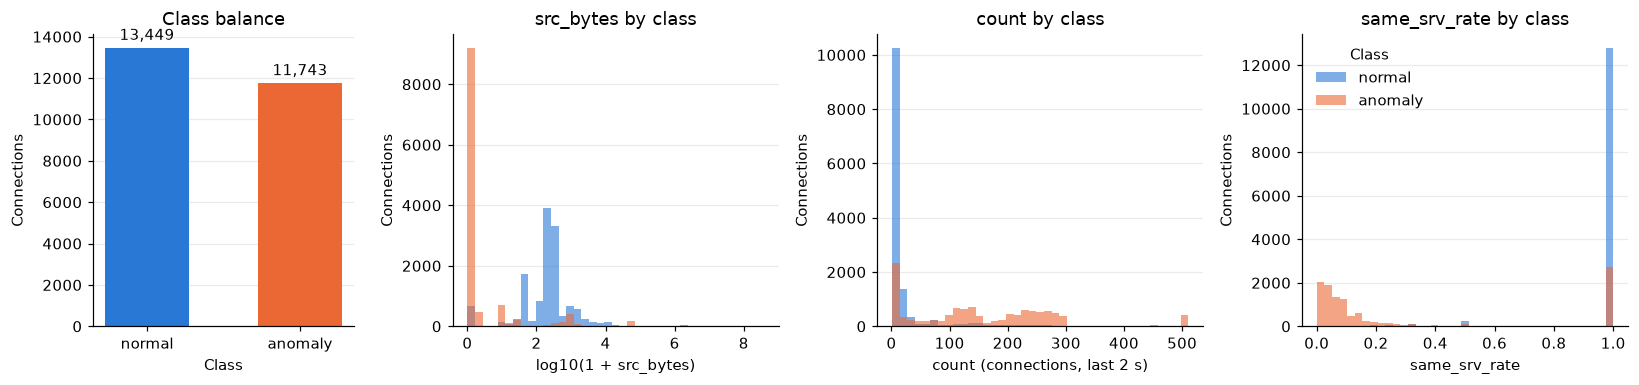

In [5]:
balance = train['class'].value_counts().reindex(CLASSES)
display(balance.to_frame('rows').assign(share=(balance / balance.sum()).round(3)))
print(f'Imbalance ratio (anomaly / normal): {balance["anomaly"] / balance["normal"]:.2f}')
display(pd.crosstab(train['service'], train['class']).reindex(index=['ssh', 'http'], columns=CLASSES, fill_value=0))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={'width_ratios': [0.8, 1, 1, 1]})
axes[0].bar(balance.index, balance.values, color=[CLASS_COLORS[c] for c in balance.index], width=0.55)
for x, value in enumerate(balance.values):
    axes[0].annotate(f'{value:,}', (x, value), ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')
axes[0].set(title='Class balance', xlabel='Class', ylabel='Connections')
for ax, column, label in [(axes[1], 'src_bytes', 'log10(1 + src_bytes)'),
                          (axes[2], 'count', 'count (connections, last 2 s)'),
                          (axes[3], 'same_srv_rate', 'same_srv_rate')]:
    values = np.log10(1 + train[column]) if column == 'src_bytes' else train[column]
    bins = np.linspace(values.min(), values.max(), 40)
    for name in CLASSES:
        ax.hist(values[train['class'] == name], bins=bins, alpha=0.6, color=CLASS_COLORS[name], label=name)
    ax.set(title=f'{column} by class', xlabel=label, ylabel='Connections')
axes[3].legend(title='Class', frameon=False)
for ax in axes:
    ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

**Reading the charts.** The two classes are close in size (about 47% anomaly), so accuracy is not misleading here. It is still not enough on its own, because it hides which kind of error a model makes. The traffic features separate the classes well: many attacks open lots of connections in two seconds (high `count`) and send little data, while normal traffic usually targets the same service repeatedly (high `same_srv_rate`). Only a few SSH rows exist, all labeled anomaly, so SSH results are reported separately and with caution.

## 3. Data preparation

Each step below is justified by what the data showed in section 2.

| Step | Decision | Why |
|---|---|---|
| Missing values | None to treat | Section 2.1 found 0 missing cells |
| Constant columns | Drop `num_outbound_cmds` and `is_host_login` | They have one value in training, so they carry no information |
| Duplicates | Keep rows, but group identical feature vectors | Removing them changes little; grouping stops the same vector appearing in both training and validation |
| Validation split | 80/20 split by group, stratified by class (the same split as `intrusion_analysis.ipynb`) | Gives an honest estimate on unseen vectors. `Test_data.csv` has no labels, so it cannot be used for evaluation |
| Categorical encoding | One-hot encoding of `protocol_type`, `service`, `flag`, ignoring unseen values | The categories have no order; one service appears only in the test file |
| Skew and scaling | `log1p` then standard scaling, for logistic regression only | Bytes and durations are extremely skewed; linear models need comparable scales. Trees split on thresholds and need neither |
| Class imbalance | No resampling | The ratio is about 0.87, so the data is nearly balanced; resampling would add noise without benefit |
| Feature selection | Compared in section 4.6: all features, the top 15 by importance, and a HoneyBadger-compatible subset | Shows whether a simpler model performs as well |

Every encoder and scaler sits inside a scikit-learn `Pipeline`, so it is fitted on the training data only.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

constant = [c for c in features if train[c].nunique() == 1]
model_features = [c for c in features if c not in constant]
categorical = [c for c in categorical if c in model_features]
numeric = [c for c in model_features if c not in categorical]
print('Dropped constant columns:', constant)
print(f'Features used: {len(model_features)} ({len(categorical)} categorical + {len(numeric)} numeric)')

X = train[model_features]
y = (train['class'] == 'anomaly').astype(int).to_numpy()   # 1 = anomaly, 0 = normal


def vector_keys(frame):
    return frame[features].astype(str).agg('|'.join, axis=1)


codes, _ = pd.factorize(pd.concat([vector_keys(train), vector_keys(test)], ignore_index=True))
train_ids, test_ids = codes[:len(train)], codes[len(train):]


def grouped_stratified_folds(groups, labels, n_folds=5, seed=SEED):
    # Fold number per row; whole groups stay in one fold; shuffled within each class with a fixed seed.
    frame = pd.DataFrame({'group': groups, 'label': np.asarray(labels)})
    group_label = frame.groupby('group')['label'].agg(lambda s: sorted(s.mode())[0])
    group_size = frame.groupby('group').size()
    rng = np.random.default_rng(seed)
    group_fold = {}
    for label in sorted(group_label.unique()):
        members = group_label.index[group_label == label].to_numpy()
        members = members[rng.permutation(len(members))]
        sizes = group_size.loc[members].to_numpy()
        starts = np.cumsum(sizes) - sizes
        group_fold.update(zip(members, starts * n_folds // sizes.sum()))
    return frame['group'].map(group_fold).to_numpy()


folds = grouped_stratified_folds(train_ids, y)
fit_idx, val_idx = np.flatnonzero(folds != 0), np.flatnonzero(folds == 0)
X_fit, X_val, y_fit, y_val = X.iloc[fit_idx], X.iloc[val_idx], y[fit_idx], y[val_idx]
assert not set(train_ids[fit_idx]) & set(train_ids[val_idx]), 'a feature vector is in both partitions'

# Inner cross-validation folds for tuning, built the same way inside the training partition only.
inner = grouped_stratified_folds(train_ids[fit_idx], y_fit, seed=SEED + 1)
inner_cv = [(np.flatnonzero(inner != k), np.flatnonzero(inner == k)) for k in range(5)]
display(pd.DataFrame({'rows': [len(fit_idx), len(val_idx)], 'anomaly share': [y_fit.mean().round(3), y_val.mean().round(3)]},
                     index=['training partition', 'validation partition']))
print('Feature vectors shared by the two partitions: 0 (checked)')


def tree_preprocessor(cat_cols):
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)], remainder='passthrough')


def linear_preprocessor(cat_cols, num_cols):
    scale = Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('scale', StandardScaler())])
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols), ('num', scale, num_cols)])

Dropped constant columns: ['num_outbound_cmds', 'is_host_login']
Features used: 39 (3 categorical + 36 numeric)


,rows,anomaly share
training partition,20153,0.466
validation partition,5039,0.466


Feature vectors shared by the two partitions: 0 (checked)


### 3.1 Export the prepared dataset
The cell below saves the prepared data as CSV files, so the result of the preparation can be inspected directly. It uses the preparation the best models use: constant columns dropped, and one-hot encoding fitted on the **training partition only**, then applied unchanged to the validation partition and the test file. Logistic regression additionally applies `log1p` and scaling inside its own pipeline.

| File | Rows | Content |
|---|---|---|
| `train_prepared.csv` | training partition | `source_row`, encoded features, `label` (1 = anomaly) |
| `validation_prepared.csv` | validation partition | `source_row`, encoded features, `label` |
| `test_prepared.csv` | all of `Test_data.csv` | `source_row`, encoded features (no label) |

`source_row` is the zero-based row number in the original CSV, so every prepared row can be traced back. In Colab the files appear in the *Files* panel.

In [7]:
from scipy import sparse

prep = tree_preprocessor(categorical).fit(X_fit)
column_names = [name.split('__', 1)[1] for name in prep.get_feature_names_out()]


def prepared_frame(frame, rows, labels=None):
    values = prep.transform(frame)
    values = values.toarray() if sparse.issparse(values) else np.asarray(values)
    out = pd.DataFrame(values, columns=column_names)
    out.insert(0, 'source_row', rows)
    if labels is not None:
        out['label'] = labels
    return out


exports = {'train_prepared.csv': prepared_frame(X_fit, fit_idx, y_fit),
           'validation_prepared.csv': prepared_frame(X_val, val_idx, y_val),
           'test_prepared.csv': prepared_frame(test[model_features], np.arange(len(test)))}
PREPARED_DIR = DATA_DIR / 'prepared' if REPO_ROOT else Path('.')
PREPARED_DIR.mkdir(parents=True, exist_ok=True)
for name, frame in exports.items():
    frame.to_csv(PREPARED_DIR / name, index=False)
    assert frame.drop(columns=['source_row', 'label'], errors='ignore').isna().sum().sum() == 0
display(pd.DataFrame({'rows': [len(f) for f in exports.values()], 'columns': [f.shape[1] for f in exports.values()]},
                     index=list(exports)))
encoded = {c: sum(n.startswith(c + '_') for n in column_names) for c in categorical}
print(f'{len(column_names)} prepared features = {len(numeric)} numeric + one-hot columns {encoded}')
print('No missing values in any prepared file. Encoder fitted on the training partition only.')
display(exports['train_prepared.csv'].iloc[:3, :8])

,rows,columns
train_prepared.csv,20153,116
validation_prepared.csv,5039,116
test_prepared.csv,22544,115


114 prepared features = 36 numeric + one-hot columns {'protocol_type': 3, 'service': 64, 'flag': 11}
No missing values in any prepared file. Encoder fitted on the training partition only.


,source_row,protocol_type_icmp,protocol_type_tcp,protocol_type_udp,service_IRC,service_X11,service_Z39_50,service_auth
0,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,1,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,2,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## 4. Modeling

### 4.1 Models and why they were chosen

| Model | Why it fits this objective |
|---|---|
| Majority-class baseline | Always predicts the most common class. It is the minimum any model must beat |
| Logistic regression | Simple linear model; its coefficients show which features push towards "attack" |
| Decision tree | Produces readable if/then rules an analyst can check |
| Random forest | Many trees voting together; usually the strongest on tabular data, robust to outliers and skew |

Hyperparameters are tuned with 5-fold grouped cross-validation **inside the training partition**, maximising anomaly F1. The validation partition is used only once, at the end.

In [8]:
import time

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

searches = {
    'Logistic regression': (Pipeline([('prep', linear_preprocessor(categorical, numeric)),
                                      ('model', LogisticRegression(max_iter=3000))]),
                            {'model__C': [0.01, 0.1, 1, 10]}),
    'Decision tree': (Pipeline([('prep', tree_preprocessor(categorical)),
                                ('model', DecisionTreeClassifier(random_state=SEED))]),
                      {'model__max_depth': [4, 8, 12, None], 'model__min_samples_leaf': [1, 5]}),
    'Random forest': (Pipeline([('prep', tree_preprocessor(categorical)),
                                ('model', RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=-1))]),
                      {'model__max_features': ['sqrt', 0.3], 'model__min_samples_leaf': [1, 3]}),
}
models, tuning = {'Majority baseline': DummyClassifier(strategy='most_frequent').fit(X_fit, y_fit)}, []
for name, (pipeline, grid) in searches.items():
    start = time.time()
    search = GridSearchCV(pipeline, grid, scoring='f1', cv=inner_cv, n_jobs=1).fit(X_fit, y_fit)
    models[name] = search.best_estimator_
    tuning.append({'model': name,
                   'best parameters': {k.replace('model__', ''): v for k, v in search.best_params_.items()},
                   'cross-validated F1': round(search.best_score_, 4),
                   'F1 std across folds': round(search.cv_results_['std_test_score'][search.best_index_], 4),
                   'tuning time (s)': round(time.time() - start, 1)})
display(pd.DataFrame(tuning).set_index('model'))

,best parameters,cross-validated F1,F1 std across folds,tuning time (s)
model,,,,
Logistic regression,{'C': 10},0.9834,0.0019,6.9
Decision tree,"{'max_depth': 12, 'min_samples_leaf': 1}",0.9963,0.0014,7.9
Random forest,"{'max_features': 0.3, 'min_samples_leaf': 1}",0.9975,0.0007,17.4


### 4.2 Evaluation on the validation partition
These rows were never used for training or tuning. Anomaly is the positive class.

In [9]:
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)


def evaluate(model, X_part, y_true):
    score = model.predict_proba(X_part)[:, 1]
    y_pred = model.predict(X_part)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'F1': f1_score(y_true, y_pred, zero_division=0),
            'accuracy': (tp + tn) / len(y_true),
            'ROC-AUC': roc_auc_score(y_true, score),
            'PR-AUC': average_precision_score(y_true, score),
            'false alarms': int(fp), 'missed attacks': int(fn),
            'attacks caught': int(tp), 'normal passed': int(tn)}


results = pd.DataFrame({name: evaluate(model, X_val, y_val) for name, model in models.items()}).T
rates = ['precision', 'recall', 'F1', 'accuracy', 'ROC-AUC', 'PR-AUC']
counts = ['false alarms', 'missed attacks', 'attacks caught', 'normal passed']
results[counts] = results[counts].astype(int)
results[rates] = results[rates].astype(float).round(4)
display(results)
best_name = results.drop(index='Majority baseline')['F1'].idxmax()
print(f'Best model by validation F1: {best_name}')

,precision,recall,F1,accuracy,ROC-AUC,PR-AUC,false alarms,missed attacks,attacks caught,normal passed
Majority baseline,0.0000,0.0000,0.0000,0.5338,0.5000,0.4662,0,2349,0,2690
Logistic regression,0.9892,0.9774,0.9833,0.9845,0.9970,0.9977,25,53,2296,2665
Decision tree,0.9966,0.9953,0.9960,0.9962,0.9947,0.9939,8,11,2338,2682
Random forest,1.0000,0.9957,0.9979,0.9980,1.0000,1.0000,0,10,2339,2690


Best model by validation F1: Random forest


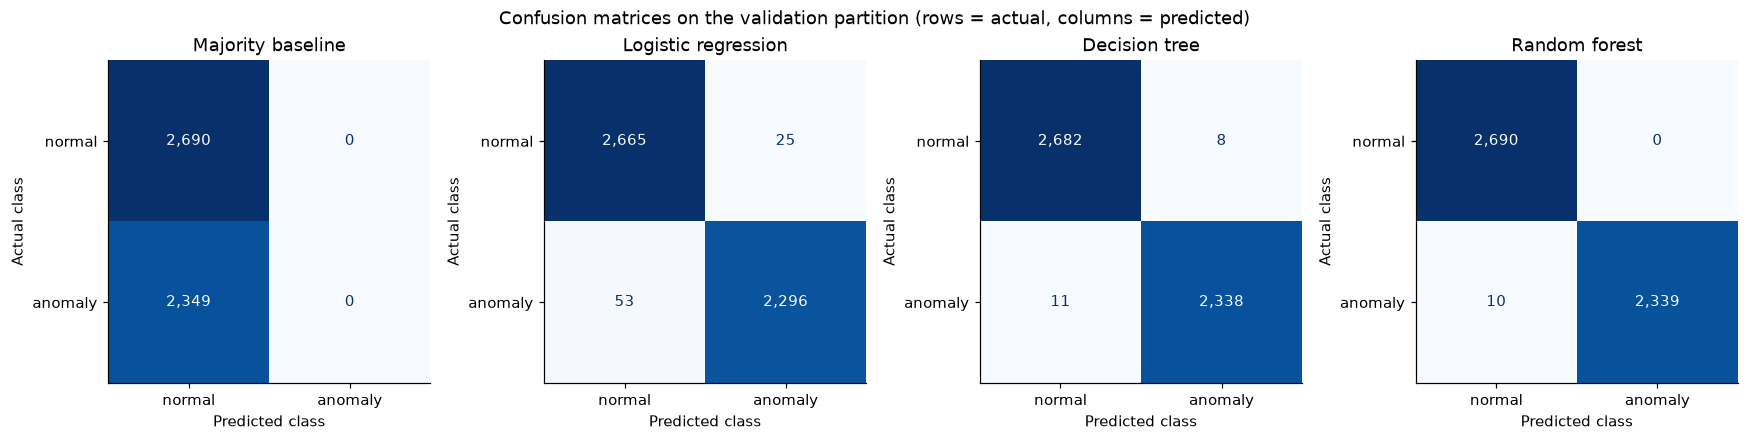

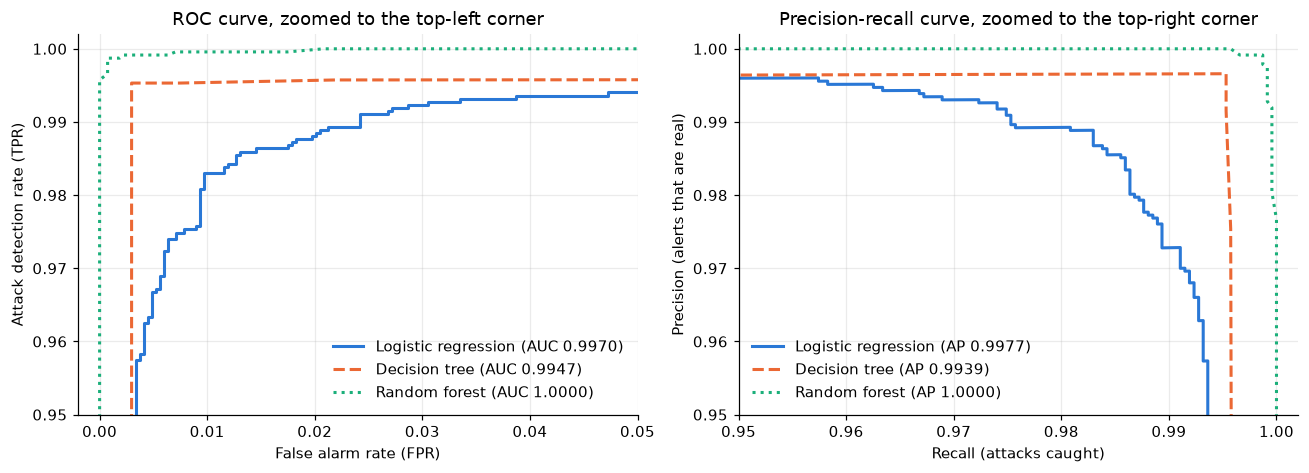

Plain-language result: the validation partition holds 2,349 attacks and 2,690 normal connections.
The random forest caught 2,339 attacks and missed 10 (recall 99.57%). It raised 0 false alarms; 100.00% of its alerts were real attacks.
The majority baseline caught 0 attacks, so every model adds real value.


In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_val, model.predict(X_val), labels=[0, 1], display_labels=CLASSES,
                                            cmap='Blues', colorbar=False, ax=ax, values_format=',')
    ax.set(title=name, xlabel='Predicted class', ylabel='Actual class')
    ax.grid(False)
fig.suptitle('Confusion matrices on the validation partition (rows = actual, columns = predicted)')
fig.tight_layout()
plt.show()

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 4.4))
for name, (color, style) in MODEL_STYLES.items():
    score = models[name].predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, score)
    precision, recall, _ = precision_recall_curve(y_val, score)
    ax_roc.plot(fpr, tpr, color=color, linestyle=style, linewidth=2, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.4f})")
    ax_pr.plot(recall, precision, color=color, linestyle=style, linewidth=2, label=f"{name} (AP {results.loc[name, 'PR-AUC']:.4f})")
ax_roc.set(title='ROC curve, zoomed to the top-left corner', xlabel='False alarm rate (FPR)', ylabel='Attack detection rate (TPR)',
           xlim=(-0.002, 0.05), ylim=(0.95, 1.002))
ax_pr.set(title='Precision-recall curve, zoomed to the top-right corner', xlabel='Recall (attacks caught)',
          ylabel='Precision (alerts that are real)', xlim=(0.95, 1.002), ylim=(0.95, 1.002))
for ax in (ax_roc, ax_pr):
    ax.legend(frameon=False, loc='lower right' if ax is ax_roc else 'lower left')
fig.tight_layout()
plt.show()

r = results.loc[best_name]
base = results.loc['Majority baseline']
n_attacks, n_normal = int(r['attacks caught'] + r['missed attacks']), int(r['normal passed'] + r['false alarms'])
print(f'Plain-language result: the validation partition holds {n_attacks:,} attacks and {n_normal:,} normal connections.')
print(f'The {best_name.lower()} caught {int(r["attacks caught"]):,} attacks and missed {int(r["missed attacks"]):,} '
      f'(recall {r["recall"]:.2%}). It raised {int(r["false alarms"]):,} false alarms; {r["precision"]:.2%} of its alerts were real attacks.')
print(f'The majority baseline caught {int(base["attacks caught"]):,} attacks, so every model adds real value.')

### 4.3 Choosing the decision threshold
By default a connection is flagged when the model's attack probability is at least 0.5. Lowering the threshold catches more attacks but raises more false alarms. The table shows this trade-off for the best model, so the security team can pick an operating point.

,recall,precision,false alarms,missed attacks
threshold,,,,
0.1,0.9996,0.9874,30,1
0.2,0.9991,0.9970,7,2
0.3,0.9983,0.9991,2,4
0.4,0.9970,0.9991,2,7
0.5,0.9957,1.0000,0,10
0.6,0.9932,1.0000,0,16
0.7,0.9915,1.0000,0,20
0.8,0.9894,1.0000,0,25
0.9,0.9808,1.0000,0,45


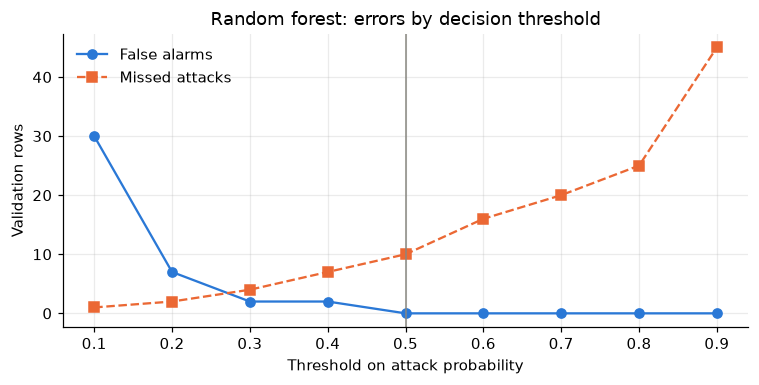

The grey line marks the default threshold of 0.5, used for every other result in this notebook.


In [11]:
best = models[best_name]
scores = best.predict_proba(X_val)[:, 1]
rows = []
for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    y_pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred, labels=[0, 1]).ravel()
    rows.append({'threshold': threshold, 'recall': tp / (tp + fn), 'precision': tp / max(tp + fp, 1),
                 'false alarms': int(fp), 'missed attacks': int(fn)})
trade_off = pd.DataFrame(rows).set_index('threshold')
display(trade_off.round(4).set_axis([f'{t:.1f}' for t in trade_off.index]).rename_axis('threshold'))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(trade_off.index, trade_off['false alarms'], color='#2a78d6', marker='o', linestyle='-', label='False alarms')
ax.plot(trade_off.index, trade_off['missed attacks'], color='#eb6834', marker='s', linestyle='--', label='Missed attacks')
ax.axvline(0.5, color='#888780', linewidth=1)
ax.set(title=f'{best_name}: errors by decision threshold', xlabel='Threshold on attack probability', ylabel='Validation rows')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
print('The grey line marks the default threshold of 0.5, used for every other result in this notebook.')

### 4.4 Interpreting the models
Three complementary views: which features the random forest relies on, which features push logistic regression towards "attack", and the first rules a shallow decision tree learns.

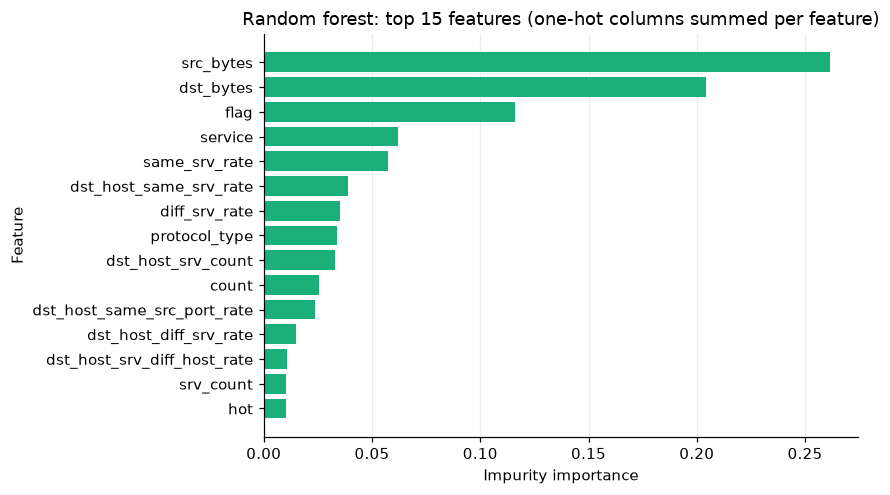

Logistic regression: strongest push towards "anomaly" (positive) and "normal" (negative)


,coefficient
service_imap4,5.704
service_private,4.503
service_pm_dump,3.921
flag_RSTOS0,3.789
flag_S0,3.666
flag_RSTR,3.637
service_IRC,-5.890
flag_REJ,-5.070
service_telnet,-5.027
service_domain_u,-4.191


Depth-3 decision tree (for explanation only; validation F1 = 0.9721):
|--- src_bytes <= 28.50
|   |--- service_http <= 0.50
|   |   |--- dst_bytes <= 2.50
|   |   |   |--- class: anomaly
|   |   |--- dst_bytes >  2.50
|   |   |   |--- class: normal
|   |--- service_http >  0.50
|   |   |--- dst_host_same_srv_rate <= 0.28
|   |   |   |--- class: anomaly
|   |   |--- dst_host_same_srv_rate >  0.28
|   |   |   |--- class: normal
|--- src_bytes >  28.50
|   |--- service_ecr_i <= 0.50
|   |   |--- hot <= 0.50
|   |   |   |--- class: normal
|   |   |--- hot >  0.50
|   |   |   |--- class: anomaly
|   |--- service_ecr_i >  0.50
|   |   |--- src_bytes <= 292.00
|   |   |   |--- class: normal
|   |   |--- src_bytes >  292.00
|   |   |   |--- class: anomaly

Importance shows what the model uses, not proof of cause.


In [12]:
from sklearn.tree import export_text


def original_feature(name):
    name = name.split('__', 1)[1]
    for column in categorical:
        if name.startswith(column + '_'):
            return column
    return name


forest = models['Random forest']
encoded = forest.named_steps['prep'].get_feature_names_out()
importance = pd.Series(forest.named_steps['model'].feature_importances_, index=encoded)
by_feature = importance.groupby([original_feature(n) for n in importance.index]).sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.6))
top = by_feature.head(15)[::-1]
ax.barh(top.index, top.values, color='#1baf7a')
ax.set(title='Random forest: top 15 features (one-hot columns summed per feature)', xlabel='Impurity importance', ylabel='Feature')
ax.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()

logistic = models['Logistic regression']
coef = pd.Series(logistic.named_steps['model'].coef_[0], index=[n.split('__', 1)[1] for n in logistic.named_steps['prep'].get_feature_names_out()])
print('Logistic regression: strongest push towards "anomaly" (positive) and "normal" (negative)')
display(pd.concat([coef.nlargest(6), coef.nsmallest(6)]).round(3).to_frame('coefficient'))

shallow = Pipeline([('prep', tree_preprocessor(categorical)),
                    ('model', DecisionTreeClassifier(max_depth=3, random_state=SEED))]).fit(X_fit, y_fit)
names = [n.split('__', 1)[1] for n in shallow.named_steps['prep'].get_feature_names_out()]
print(f'Depth-3 decision tree (for explanation only; validation F1 = {f1_score(y_val, shallow.predict(X_val)):.4f}):')
print(export_text(shallow.named_steps['model'], feature_names=names, class_names=CLASSES))
print('Importance shows what the model uses, not proof of cause.')

### 4.5 Results by service
Overall scores can hide gaps. SSH and HTTP are the two services HoneyBadger emulates.

In [13]:
val_service = X_val['service'].to_numpy()
group = np.where(np.isin(val_service, ['ssh', 'http']), val_service, 'other services')
pred = best.predict(X_val)
rows = {}
for name in ['ssh', 'http', 'other services']:
    mask = group == name
    t, p = y_val[mask], pred[mask]
    rows[name] = {'rows': int(mask.sum()), 'actual attacks': int(t.sum()), 'actual normal': int((t == 0).sum()),
                  'recall': recall_score(t, p, zero_division=0) if t.sum() else np.nan,
                  'false alarms': int(((p == 1) & (t == 0)).sum()), 'missed attacks': int(((p == 0) & (t == 1)).sum())}
display(pd.DataFrame.from_dict(rows, orient='index').round({'recall': 4}))
print('SSH has no normal rows in this data, so SSH false alarms cannot be measured.')

,rows,actual attacks,actual normal,recall,false alarms,missed attacks
ssh,6,6,0,1.0000,0,0
http,1586,89,1497,0.9888,0,1
other services,3447,2254,1193,0.9960,0,9


SSH has no normal rows in this data, so SSH false alarms cannot be measured.


### 4.6 Feature selection, and the HoneyBadger question
Three random forests with the same tuned settings, each trained on a different feature set:

1. **All features** (39 after dropping the constant columns).
2. **Top 15 features** by importance. Importance is computed on the training partition only, so the validation data plays no part in the choice.
3. **HoneyBadger-compatible features**: features whose idea HoneyBadger records or could derive from its event log (service, login outcome, and connection counts over time). It excludes bytes, durations, TCP flags and error rates, which the honeypot does not capture. This is an approximation: HoneyBadger would compute the counts per source IP, not exactly as KDD does, and every SSH login it receives succeeds.

In [14]:
HONEYBADGER_FEATURES = ['service', 'num_failed_logins', 'logged_in', 'count', 'srv_count', 'same_srv_rate',
                        'diff_srv_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
                        'dst_host_diff_srv_rate']
top15 = by_feature.head(15).index.tolist()
best_rf_params = {k.replace('model__', ''): v for k, v in models['Random forest'].named_steps['model'].get_params().items()
                  if k in ('max_features', 'min_samples_leaf')}
comparison = {}
for label, columns in [('All features', model_features), ('Top 15 features', top15),
                       ('HoneyBadger-compatible', HONEYBADGER_FEATURES)]:
    cats = [c for c in categorical if c in columns]
    max_features = best_rf_params['max_features']
    rf = Pipeline([('prep', tree_preprocessor(cats)),
                   ('model', RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=-1,
                                                    max_features=max_features,
                                                    min_samples_leaf=best_rf_params['min_samples_leaf']))])
    rf.fit(X_fit[columns], y_fit)
    comparison[label] = {'features': len(columns), **evaluate(rf, X_val[columns], y_val)}
comparison = pd.DataFrame(comparison).T
comparison[['features'] + counts] = comparison[['features'] + counts].astype(int)
display(comparison[['features', 'precision', 'recall', 'F1', 'PR-AUC', 'false alarms', 'missed attacks']].round(4))
print('Top 15 features:', top15)
drop = comparison.loc['All features', 'F1'] - comparison.loc['HoneyBadger-compatible', 'F1']
print(f'Using only HoneyBadger-compatible features changes F1 by {-drop:+.4f}.')

,features,precision,recall,F1,PR-AUC,false alarms,missed attacks
All features,39,1.0000,0.9957,0.9979,1.0000,0,10
Top 15 features,15,0.9996,0.9953,0.9974,1.0000,1,11
HoneyBadger-compatible,11,0.9909,0.9762,0.9835,0.9959,21,56


Top 15 features: ['src_bytes', 'dst_bytes', 'flag', 'service', 'same_srv_rate', 'dst_host_same_srv_rate', 'diff_srv_rate', 'protocol_type', 'dst_host_srv_count', 'count', 'dst_host_same_src_port_rate', 'dst_host_diff_srv_rate', 'dst_host_srv_diff_host_rate', 'srv_count', 'hot']
Using only HoneyBadger-compatible features changes F1 by -0.0144.


## 5. Predictions on the unlabeled test file
The best model is refitted on **all** labeled rows with its tuned settings, then predicts every row of `Test_data.csv`. The test file has no labels, so no metric can be computed on it. The export keeps the original row order.

In [15]:
from sklearn.base import clone

final_model = clone(models[best_name]).fit(X, y)
probability = final_model.predict_proba(test[model_features])[:, 1]
result = pd.DataFrame({'test_row': np.arange(len(test)),
                       'predicted_class': np.where(probability >= 0.5, 'anomaly', 'normal'),
                       'anomaly_probability': probability.round(4),
                       'seen_in_training': np.isin(test_ids, train_ids)})
result.to_csv(PREDICTIONS_FILE, index=False)
check = pd.read_csv(PREDICTIONS_FILE)
assert len(check) == len(test) and check['test_row'].tolist() == list(range(len(test)))
print(f'{best_name} refitted on {len(X):,} labeled rows; saved {len(check):,} predictions to {PREDICTIONS_FILE}.')
display(result['predicted_class'].value_counts().to_frame('test rows'))
if IN_COLAB:
    from google.colab import files
    files.download(str(PREDICTIONS_FILE))

Random forest refitted on 25,192 labeled rows; saved 22,544 predictions to ..\results\predictions\pair1_predictions.csv.


,test rows
predicted_class,
normal,13927
anomaly,8617


### Save the results
The settings and every measured number are written to `results/pair1_results.json`. `scripts/run_analysis.py` re-runs this notebook and compares that file with the reference values, so anyone can check the results are reproduced.

In [16]:
import json
import platform

RESULTS_DIR.mkdir(exist_ok=True)
to_plain = lambda o: o.item() if hasattr(o, 'item') else str(o)
record = {
    'notebook': 'notebooks/pair1_attack_classification.ipynb',
    'environment': {'python': platform.python_version(), 'pandas': pd.__version__,
                    'scikit-learn': sklearn.__version__, 'numpy': np.__version__},
    'data': {name: {'sha256': sha, 'bytes': size} for name, (sha, size) in EXPECTED_FILES.items()},
    'config': {'seed': SEED, 'training_rows': int(len(fit_idx)), 'validation_rows': int(len(val_idx)),
               'validation_attacks': int(y_val.sum()), 'dropped_constant_columns': constant,
               'tuned_parameters': {row['model']: row['best parameters'] for row in tuning},
               'decision_threshold': 0.5},
    'best_model': best_name,
    'validation_metrics': results.round(4).to_dict(orient='index'),
    'feature_selection': comparison.round(4).to_dict(orient='index'),
    'test_predictions': {'rows': int(len(result)),
                         'predicted_anomaly': int((result['predicted_class'] == 'anomaly').sum())},
}
(RESULTS_DIR / 'pair1_results.json').write_text(json.dumps(record, indent=2, sort_keys=True, default=to_plain))
print('Saved results/pair1_results.json')

Saved results/pair1_results.json


## 6. Conclusion

**Answer to the business question.** Supervised models detect attacks in this dataset very reliably. All three beat the majority baseline by a wide margin. The best model (section 4.2) catches over 99% of the attacks in the validation partition with very few false alarms, which meets the success criteria set in section 1. The threshold table (4.3) lets the security team trade false alarms against missed attacks.

**What drives detection.** The random forest relies most on the bytes sent in each direction, the TCP flag, the service and the same-service rates (section 4.4). The shallow tree shows the same idea in plain rules: connections that send almost no data are suspicious unless the server answers. This matches known attack behaviour such as floods and scans, which open many connections that carry little data.

**For HoneyBadger (section 4.6).** A model limited to features the honeypot could derive still detects most attacks, but it is clearly weaker than the full model: it misses more attacks and raises more false alarms, because it has no byte counts or TCP flags. Building connection-count features from HoneyBadger's events (`service`, `source_ip`, `timestamp`, login data) is worthwhile, and adding session byte counts to the honeypot would help most.

**Limitations**
- The scores come from this Kaggle dataset, not from HoneyBadger's own events. They show the method works, not that it works on our honeypot.
- The labeled SSH rows are all attacks, so SSH false alarms cannot be measured.
- The dataset only labels normal or anomaly; it does not identify the attack type.
- The test file has no labels, so its predictions cannot be scored.

**Next step.** Export HoneyBadger events, compute the HoneyBadger-compatible features per session, label a sample by hand, and evaluate the model on that.